# Nevis — RIA Market Analysis from SEC Form ADV data (2021 → 2026)

**Author:** George Triplett · **Data:** SEC Form ADV Part 1A bulk snapshots, Sept 2021 – Sept 2026

This notebook (1) parses five years of SEC Form ADV data into a clean firm-year table of every
SEC-registered investment adviser, and (2) answers Nevis's three business questions within each
AUM segment: **who is growing fastest, who is capacity-strained, and who looks under-staffed**.

**How to read it:** the executive summary comes first; each section then gives the method, the
code and a short commentary. Every number in the summary is printed by a cell further down.

**Structure**
1. Setup & data acquisition
2. Parse & clean → firm-year panel (with a data-quality log)
3. The analysis-ready data table (all 12 required fields + extras)
4. Market segments
5. Q1 — Fastest-growing firms (1, 3, 5 years)
6. Q2 — Capacity-strained firms (AUM per advisor)
7. Q3 — Under-staffed firms (AUM growth vs advisor growth)
8. So what for Nevis — market structure & a prioritised target list
9. Assumptions, edge cases & limitations

## Executive summary

**The data.** 95,020 firm-year rows covering 21,485 SEC-registered advisers (Sept 2021 → Sept 2026),
with all 12 required fields plus extras (client mix, succession, quality flags). 17,210 firms filed
in 2026, managing $177.9T in regulatory AUM.

**Market structure (2026).** The count is in the long tail, the money is at the top:

| Segment | Firms | of which wealth managers* | Share of AUM |
|---|---|---|---|
| <$1B | 11,820 | 7,537 (64%) | 2% |
| $1B–$10B | 4,019 | 1,467 (37%) | 7% |
| $10B–$50B | 939 | 156 (17%) | 12% |
| >$50B | 432 | 61 (14%) | 79% |

\* ≥50% of AUM from individuals / high-net-worth clients, i.e. the firms whose workflow Nevis serves.

**Q1 — Growth.** The median firm grew AUM ~14–15% in the last year in every segment (mostly market
beta). The fastest *organic* growers compound at 60–135% a year, 4–10× the median. Raw leaderboards
are polluted by re-registrations and acquisitions, so the notebook ranks organic growth separately
and shows an M&A-inclusive view next to it (1–6% of ranked firms are flagged).

**Q2 — Capacity.** Among advice-led wealth managers (platforms and robo-advisers excluded), the most
strained firms carry 4–40× their segment's median AUM per advisor.

**Q3 — Under-staffing is the norm, not the exception.** 73–78% of established firms grew AUM faster
than advisor headcount over 1, 3 and 5 years. For the median wealth manager, AUM per advisor rose
~27% ($60M → $76M) while clients per advisor rose only ~9% (58 → 63): each advisor is managing more
money per relationship, which is exactly the leverage problem AI tooling addresses.

**So what for Nevis.** A composite score (growth × staffing gap × client load) over 1,349 qualifying
firms produces a prioritised target list, with a separate enterprise (≥$10B) list led by firms such as
Concentric, Aptus, AE Wealth and O'Shaughnessy. These are firms that are growing, stretched, and
structurally in need of leverage per advisor.

**Main caveat.** Form ADV counts "advisors" as employees doing investment advisory work (Item 5.B(1)),
which includes analysts and portfolio staff, not only client-facing advisors. Ratios are best read
as relative within a segment, not as absolute workloads.

## 1. Setup & data acquisition

**Source.** The SEC publishes a monthly snapshot of the latest Form ADV Part 1A for every
SEC-registered adviser ([link](https://www.sec.gov/data-research/sec-markets-data/information-about-registered-investment-advisers-exempt-reporting-advisers)).
Each row is one firm, as of its most recent filing.

**Which files.** One snapshot per year, all from early September, so that the 1-, 3- and 5-year
comparisons are exactly 12, 36 and 60 months apart:

| Year | SEC file | Snapshot date |
|---|---|---|
| 2021 | `ia090121.zip` | 1 Sep 2021 |
| 2022 | `ia090122.zip` | 1 Sep 2022 |
| 2023 | `ia090623.xlsx` | 6 Sep 2023 |
| 2024 | `ia090324.xlsx` | 3 Sep 2024 |
| 2025 | `ia09022025.xlsx` | 2 Sep 2025 |
| 2026 | `ia100226.zip` (contains the 1 Sep 2026 extract) | 1 Sep 2026 |

`scripts/download_data.py` fetches these into `data/raw/`. Parsing logic lives in
`src/ria_adv.py` so the notebook stays readable and the cleaning rules are testable in one place.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
import ria_adv as adv  # noqa: E402

RAW, CACHE, OUT = ROOT / "data/raw", ROOT / "data/processed/cache", ROOT / "outputs"
OUT.mkdir(exist_ok=True)

LATEST = 2026
SEGMENTS = adv.SEGMENT_LABELS

# --- analysis thresholds (all in one place so they are easy to challenge) ---
MIN_BASE_AUM = 100e6       # growth is only ranked when the base-year AUM was >= $100M
MIN_BASE_ADVISORS = 5      # staffing-gap ranking needs >= 5 advisors in the base year
MIN_ADVISORS_CAPACITY = 3  # capacity ranking ignores 1–2 person shops (portfolio-manager boutiques)
TOP_N = 5                  # rows shown per segment in the notebook (full top-25 lists go to Excel)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

# chart style: one hue, recessive grid
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c3", "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
                     "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "font.size": 10})

print("files in data/raw:")
for f in sorted(RAW.iterdir()):
    print(f"  {f.name:<18} {f.stat().st_size/1e6:6.1f} MB")

files in data/raw:
  ia090121.zip          3.4 MB
  ia090122.zip          3.6 MB
  ia09022025.xlsx      20.5 MB
  ia090324.xlsx        20.0 MB
  ia090623.xlsx        19.5 MB
  ia100226.zip          6.0 MB


## 2. Parse & clean → firm-year panel

**What the parser does** (`adv.build_panel`):

| Step | Rule | Why |
|---|---|---|
| Read | Only the ~60 Form ADV items we need, all read as text | Avoids pandas silently mangling SEC numbers, ZIPs and dollar strings |
| Encode | CSV files are Windows-1252 | Firm names with accents otherwise fail to parse |
| Key | `SEC#` must match `801-XXXXX`; one row per firm-year (latest filing wins) | Stable firm key across years |
| Dollars | Strip `$`, commas → float | AUM is stored as `"1,432,805,003.00"` |
| Dates | Mixed formats (`MM/DD/YYYY` in CSVs, ISO in Excel) | Excel and CSV years export dates differently |
| Website | Normalise to `www.domain.com`; drop social/app links; across all six years pick the domain that matches the firm's name, else the latest valid one (`website_source` records which) | The bulk file carries only one of a firm's URLs per year, often a social profile or an unrelated page |
| Clients | Σ Item 5.D(1) client counts over all 14 client types + Item 5.C(1) (clients with no AUM, e.g. planning-only) | Item 5 has no single "total clients" field |
| Client edge cases | "Fewer than 5" boxes → impute 2; 5.C(1) values that are really dollar amounts → dropped | See QA log below |
| Advisors | Item 5.B(1): employees who perform investment advisory functions | Closest Form ADV proxy for advisor headcount |
| Wealth flag | ≥ 50% of AUM from individuals + high-net-worth individuals (Items 5.D(a)(3)+(b)(3)) | Separates wealth managers (Nevis's ICP) from institutional asset managers |
| Platform flag | > 1,000 clients per advisor → `digital_or_platform` (robo-advisers, managed-account platforms, TAMPs) | Their "advisors" aren't client-facing; excluded from capacity rankings and targets |
| Ratios | AUM/client, AUM/advisor, clients/advisor are NaN when the denominator is 0 | No divide-by-zero infinities in rankings |

In [2]:
panel, qa = adv.build_panel(RAW, cache_dir=CACHE)

qa_flags = panel.groupby("year").agg(
    clients_5c_dollar_typo=("clients_5c_invalid_flag", "sum"),
    firms_with_lt5_imputation=("clients_imputed_flag", "sum"),
    website_found=("website", lambda s: f"{s.notna().mean():.0%}"),
    website_backfilled=("website_filled_flag", "sum"),
).reset_index()
qa.merge(qa_flags, on="year")

,year,file,rows_raw,invalid_sec_number,duplicates_removed,firms,missing_aum,zero_aum,zero_or_missing_advisors,clients_5c_dollar_typo,firms_with_lt5_imputation,website_found,website_backfilled
0,2021,ia090121.zip,14638,0,0,14638,0,690,177,3,3852,82%,2860
1,2022,ia090122.zip,15362,0,0,15362,0,651,178,8,3766,82%,3391
2,2023,ia090623.xlsx,15528,0,0,15528,0,652,178,7,3662,82%,3681
3,2024,ia090324.xlsx,15923,0,0,15923,0,689,152,6,3680,82%,3950
4,2025,ia09022025.xlsx,16359,0,0,16359,0,628,129,11,3700,82%,4000
5,2026,ia100226.zip,17210,0,0,17210,0,659,133,7,3755,80%,3780


**Reading the QA log.** Every snapshot parses cleanly: no invalid or duplicate SEC numbers,
no missing AUM. About 4% of firms report $0 regulatory AUM (pure financial-planning or
consulting advisers). They stay in the table but drop out of the growth and ratio rankings.
A handful of filers each year typed a dollar figure into the 5.C(1) "number of clients"
box, for example one firm reporting 2.36 *billion* clients, exactly equal to its AUM. Left in,
those few rows would inflate the industry client total about 35×, so they are neutralised and flagged.

**Sanity check: industry totals over time.** If the parse were wrong, these would jump
around. Instead they move smoothly. (Regulatory AUM double-counts sub-advised assets, so it is
larger than "wealth" AUM figures quoted in the press.)

In [3]:
totals = (panel.groupby("year")
          .agg(firms=("sec_number", "nunique"), aum_tn=("aum", lambda s: s.sum() / 1e12),
               clients_m=("clients", lambda s: s.sum() / 1e6), employees_k=("employees", lambda s: s.sum() / 1e3),
               advisors_k=("advisors", lambda s: s.sum() / 1e3))
          .round(1))
totals

,firms,aum_tn,clients_m,employees_k,advisors_k
year,,,,,
2021,14638,111.8,58.3,886.4,468.8
2022,15362,128.1,63.5,981.6,503.2
2023,15528,125.2,60.8,972.4,524.4
2024,15923,128.3,62.3,1005.0,532.5
2025,16359,144.0,67.5,1035.2,551.8
2026,17210,177.9,71.5,1113.9,591.3


**Spot check against a known firm.** The brief uses Beacon Pointe as its website example.
Here it is across all six years. Note that its only website in the bulk file is a social
profile, so `website` is blank and `social_url` carries the link. This is a known limitation of
the bulk file (Section 9).

In [4]:
cols = ["year", "sec_number", "firm_name", "city", "state", "aum", "clients", "employees",
        "advisors", "filing_date", "website", "social_url"]
panel.loc[panel["firm_name"].str.contains("BEACON POINTE", na=False), cols]

,year,sec_number,firm_name,city,state,aum,clients,employees,advisors,filing_date,website,social_url
13029,2021,801-60943,"BEACON POINTE ADVISORS, LLC",NEWPORT BEACH,CA,1.244199e+10,6008.0,211.0,141.0,2021-08-03,NaN,https://www.linkedin.com/company/the-sense
21206,2022,801-60943,"BEACON POINTE ADVISORS, LLC",NEWPORT BEACH,CA,2.367454e+10,10757.0,350.0,200.0,2022-03-30,NaN,https://www.linkedin.com/company/the-sense
45480,2023,801-60943,"BEACON POINTE ADVISORS, LLC",NEWPORT BEACH,CA,2.324573e+10,13436.0,420.0,230.0,2023-09-05,NaN,https://www.linkedin.com/company/the-sense
59875,2024,801-60943,"BEACON POINTE ADVISORS, LLC",NEWPORT BEACH,CA,3.127996e+10,15051.0,500.0,296.0,2024-08-06,NaN,https://www.linkedin.com/company/the-sense
76759,2025,801-60943,"BEACON POINTE ADVISORS, LLC",NEWPORT BEACH,CA,3.983976e+10,18642.0,600.0,355.0,2025-07-15,NaN,https://www.linkedin.com/company/the-sense
92993,2026,801-60943,"BEACON POINTE ADVISORS, LLC",NEWPORT BEACH,CA,5.487253e+10,30194.0,780.0,440.0,2026-08-31,NaN,https://www.linkedin.com/company/the-sense


## 3. The analysis-ready data table

One row per firm per year with the 12 required fields, plus a few extras that the business
questions need:

* `segment`: AUM band, so every question can be answered within segment
* `wealth_manager`, `pct_aum_individuals`, `pct_aum_hnw`: who is a wealth manager vs an
  institutional asset manager. This matters because "AUM per advisor" means something very
  different at an index-fund manager than at an RIA serving families.
* `clients_per_advisor`: a second capacity measure. Admin workload (the work Nevis automates)
  scales with client relationships, not just dollars.
* `crd`, `legal_name`, `snapshot_date`, `source_file`: traceability back to the SEC record

The full panel is saved to `outputs/ria_panel_2021_2026.csv`, and the latest year with all
growth metrics to `outputs/nevis_ria_analysis.xlsx`.

In [5]:
panel["segment"] = adv.assign_segment(panel["aum"])

REQUIRED = {
    "sec_number": "SEC#", "firm_name": "Firm Name", "website": "Website", "city": "City",
    "state": "State", "aum": "AUM (USD)", "clients": "Number of Clients",
    "aum_per_client": "Avg AUM per Client (USD)", "employees": "Number of Employees",
    "advisors": "Number of Advisors", "aum_per_advisor": "AUM per Advisor (USD)",
    "filing_date": "Filing Date", "year": "Year",
}
EXTRA = ["segment", "wealth_manager", "digital_or_platform", "pct_aum_individuals", "pct_aum_hnw",
         "clients_per_advisor", "website_source", "social_url", "crd", "legal_name", "sec_status", "snapshot_date", "source_file",
         "clients_imputed_flag", "clients_5c_invalid_flag", "website_filled_flag", "succession_flag"]

EXTRA_NAMES = {
    "segment": "Segment", "wealth_manager": "Wealth Manager", "digital_or_platform": "Digital or Platform",
    "pct_aum_individuals": "% AUM Individuals", "pct_aum_hnw": "% AUM HNW",
    "clients_per_advisor": "Clients per Advisor", "website_source": "Website Source",
    "social_url": "Social URL", "crd": "CRD#", "legal_name": "Legal Name", "sec_status": "SEC Status",
    "snapshot_date": "Snapshot Date", "source_file": "Source File",
    "clients_imputed_flag": "Flag: Clients Imputed", "clients_5c_invalid_flag": "Flag: Client Count Typo Removed",
    "website_filled_flag": "Flag: Website From Another Year", "succession_flag": "Flag: Succession",
}


def tidy(df: pd.DataFrame) -> pd.DataFrame:
    """Presentation rounding for exports: whole dollars and counts, 1 dp ratios, 4 dp shares/rates."""
    df = df.copy()
    whole = ["aum", "clients", "employees", "advisors", "aum_per_client", "aum_per_advisor", "crd"]
    whole += [c for c in df.columns if c.startswith(("aum_", "advisors_", "clients_")) and c.endswith("y_ago")]
    for c in whole:
        if c in df:
            df[c] = df[c].round(0).astype("Int64")
    for c in df.columns:
        if c == "clients_per_advisor":
            df[c] = df[c].round(1)
        elif c.startswith(("pct_", "aum_cagr", "advisor_cagr", "clients_cagr", "staffing_gap", "nevis_score")):
            df[c] = df[c].round(4)
    return df


table = panel[list(REQUIRED) + EXTRA].sort_values(["year", "aum"], ascending=[False, False])
tidy(table).rename(columns={**REQUIRED, **EXTRA_NAMES}).to_csv(OUT / "ria_panel_2021_2026.csv", index=False)

print(f"{len(table):,} firm-year rows · {table['sec_number'].nunique():,} distinct firms · "
      f"{len(table.columns)} columns → outputs/ria_panel_2021_2026.csv")
table[table["year"] == LATEST].head(10).rename(columns=REQUIRED).iloc[:, :13]

95,020 firm-year rows · 21,485 distinct firms · 30 columns → outputs/ria_panel_2021_2026.csv


,SEC#,Firm Name,Website,City,State,AUM (USD),Number of Clients,Avg AUM per Client (USD),Number of Employees,Number of Advisors,AUM per Advisor (USD),Filing Date,Year
94073,801-11953,VANGUARD GROUP INC,NaN,MALVERN,PA,1.109267e+13,228.0,4.865204e+10,1702.0,19.0,5.838245e+11,2026-09-21,2026
94076,801-134586,"VANGUARD CAPITAL MANAGEMENT, LLC",NaN,MALVERN,PA,8.436182e+12,128.0,6.590767e+10,235.0,235.0,3.589865e+10,2026-09-21,2026
91440,801-7884,FIDELITY MANAGEMENT & RESEARCH COMPANY LLC,NaN,BOSTON,MA,5.685042e+12,36653.0,1.551044e+08,1427.0,744.0,7.641185e+09,2026-07-30,2026
94486,801-8055,CAPITAL RESEARCH AND MANAGEMENT COMPANY,retirementsolutions.financialtrans.com,LOS ANGELES,CA,4.320750e+12,23712.0,1.822179e+08,1395.0,411.0,1.051277e+10,2026-09-25,2026
88372,801-22609,BLACKROCK FUND ADVISORS,NaN,SAN FRANCISCO,CA,4.282224e+12,531.0,8.064453e+09,128.0,122.0,3.510020e+10,2026-05-15,2026
92856,801-48187,PACIFIC INVESTMENT MANAGEMENT COMPANY LLC,www.pimco.com,NEWPORT BEACH,CA,3.666935e+12,41704.0,8.792766e+07,1968.0,628.0,5.839069e+09,2026-08-28,2026
92707,801-21011,J.P. MORGAN INVESTMENT MANAGEMENT INC.,am.jpmorgan.com,NEW YORK,NY,3.519415e+12,129024.0,2.727721e+07,3194.0,2260.0,1.557263e+09,2026-08-26,2026
94088,801-134587,"VANGUARD PORTFOLIO MANAGEMENT, LLC",NaN,MALVERN,PA,2.656484e+12,101.0,2.630182e+10,105.0,105.0,2.529984e+10,2026-09-21,2026
94455,801-37591,"GOLDMAN SACHS ASSET MANAGEMENT, L.P.",www.petershillpartners.com,NEW YORK,NY,2.648903e+12,121430.0,2.181424e+07,2059.0,1379.0,1.920887e+09,2026-09-25,2026
90293,801-856,"T. ROWE PRICE ASSOCIATES, INC.",www.troweprice.com,BALTIMORE,MD,2.196453e+12,6974.0,3.149488e+08,3760.0,545.0,4.030188e+09,2026-07-06,2026


## 4. Market segments (latest year, Sept 2026)

In [6]:
latest = panel[panel["year"] == LATEST]
seg = (latest.groupby("segment", observed=True)
       .agg(firms=("sec_number", "count"),
            wealth_managers=("wealth_manager", "sum"),
            aum_tn=("aum", lambda s: s.sum() / 1e12),
            median_aum_m=("aum", lambda s: s.median() / 1e6),
            median_advisors=("advisors", "median"),
            median_clients=("clients", "median")))
seg["share_of_firms"] = seg["firms"] / seg["firms"].sum()
seg["share_of_aum"] = seg["aum_tn"] / seg["aum_tn"].sum()
seg["pct_wealth_managers"] = seg["wealth_managers"] / seg["firms"]
seg.loc["Total"] = [seg["firms"].sum(), seg["wealth_managers"].sum(), seg["aum_tn"].sum(),
                    latest["aum"].median() / 1e6, latest["advisors"].median(),
                    latest["clients"].median(), 1.0, 1.0,
                    seg["wealth_managers"].sum() / seg["firms"].sum()]

fmt = seg.copy()
for c in ["firms", "wealth_managers", "median_advisors", "median_clients"]:
    fmt[c] = fmt[c].map("{:,.0f}".format)
fmt["aum_tn"] = fmt["aum_tn"].map("${:,.1f}T".format)
fmt["median_aum_m"] = fmt["median_aum_m"].map("${:,.0f}M".format)
for c in ["share_of_firms", "share_of_aum", "pct_wealth_managers"]:
    fmt[c] = fmt[c].map("{:.0%}".format)
fmt

,firms,wealth_managers,aum_tn,median_aum_m,median_advisors,median_clients,share_of_firms,share_of_aum,pct_wealth_managers
segment,,,,,,,,,
<$1B,"11,820","7,537",$3.7T,$240M,3,113,69%,2%,64%
$1B-$10B,"4,019","1,467",$12.4T,"$2,266M",12,40,23%,7%,37%
$10B-$50B,939,156,$20.9T,"$18,905M",37,61,5%,12%,17%
>$50B,432,61,$140.9T,"$125,507M",128,230,3%,79%,14%
Total,"17,210","9,221",$177.9T,$416M,5,99,100%,100%,54%


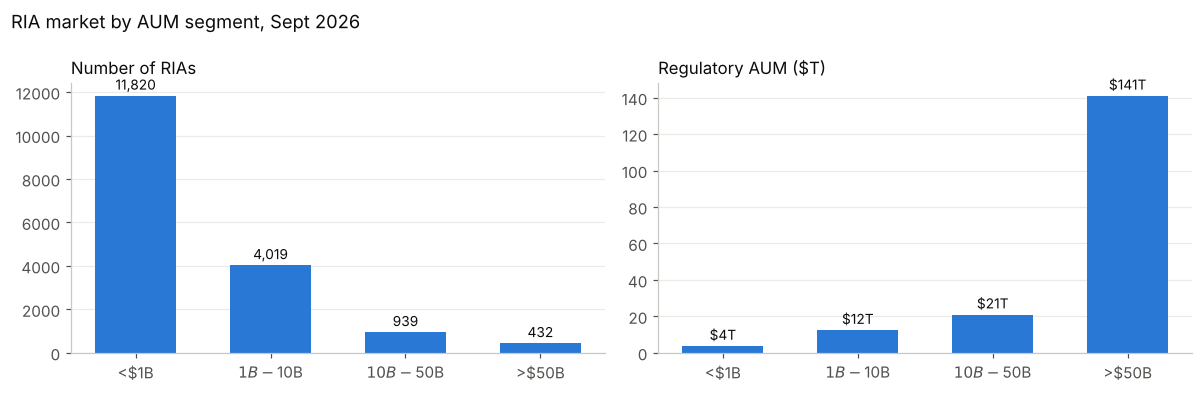

In [7]:
s = seg.drop("Total")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in [(axes[0], "firms", "Number of RIAs"), (axes[1], "aum_tn", "Regulatory AUM ($T)")]:
    bars = ax.bar(s.index.astype(str), s[col], color=BLUE, width=0.6)
    ax.set_title(title, loc="left", fontsize=11)
    for b, v in zip(bars, s[col]):
        ax.annotate(f"{v:,.0f}" if col == "firms" else f"${v:,.0f}T", (b.get_x() + b.get_width() / 2, v),
                    ha="center", va="bottom", fontsize=9, color=INK, xytext=(0, 2), textcoords="offset points")
    ax.grid(axis="x", visible=False)
fig.suptitle(f"RIA market by AUM segment, Sept {LATEST}", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()

**Market structure in one line:** the market is a long tail by count and concentrated by dollars.
About 69% of the ~17,200 RIAs manage under $1B, but the ~430 firms above $50B hold most of the
regulatory AUM. The bigger the segment, the less "wealth management" it is: most firms under $1B
are wealth managers, but most firms above $10B are institutional asset managers
(funds, pensions, insurers). **For Nevis, segment by AUM *and* by client type.** The
`wealth_manager` flag is what turns a list of 17,000 advisers into a list of real prospects.

## 5. Q1 — Who are the fastest-growing firms?

**Method.**
* Growth is the **compound annual growth rate (CAGR)** of regulatory AUM between the September
  snapshots: 2025→2026 (1y), 2023→2026 (3y) and 2021→2026 (5y). Total growth is shown alongside.
* A firm is ranked only if it existed in the base year **and** had ≥ $100M AUM then. Otherwise
  a firm going from $2M to $900M "grows 45,000%" and crowds out every real story.
* Segment = **current** (2026) AUM, so this answers "who are the fastest growers among today's
  $1–10B firms".
* **Organic vs. structural growth.** Some AUM jumps aren't growth in the commercial sense:
  * a new SEC registrant taking over an affiliate's book (e.g. a bank moving its wealth arm into a new entity)
  * a fund launch or a roll-up

  Two flags catch these:
  * `step_change`: AUM more than tripled in a single year inside the window
  * `succession_any`: the firm reported succeeding to another adviser's business (Item 4.A)

  The **headline tables below rank organic growers only** (neither flag). The flagged firms are
  shown once afterwards, and all lists are in the Excel workbook. M&A-driven firms are still
  excellent prospects, since integration is a buying moment, but they need a different story.
* **Market context:** median AUM growth was ~15% in the last year in every segment. A firm has
  to beat that to be taking share.

In [8]:
g = adv.growth_table(panel, LATEST)


def money(x):
    if pd.isna(x):
        return ""
    return f"${x/1e9:,.1f}B" if abs(x) >= 1e9 else f"${x/1e6:,.0f}M"


def pct(x):
    return "" if pd.isna(x) else f"{x:+.0%}"


def hq(t):
    """City, State for US firms; City, Country for non-US firms."""
    region = t["state"].where(t["state"].str.len() > 0, t["country"].str.title())
    return t["city"].str.title() + ", " + region


def flag(t, h):
    return np.where(t[f"step_change_{h}y"] | t["succession_any"], "M&A / step change", "")


def top_by_segment(df, sort_col, n, ascending=False):
    return (df.sort_values(sort_col, ascending=ascending)
              .groupby("segment", observed=True, group_keys=False).head(n)
              .sort_values(["segment", sort_col], ascending=[True, ascending]))


def fastest(h, n=TOP_N, organic=True):
    d = g[(g[f"aum_{h}y_ago"] >= MIN_BASE_AUM) & g[f"aum_cagr_{h}y"].notna()]
    d = d[~d[f"step_change_{h}y"] & ~d["succession_any"]] if organic else d
    return top_by_segment(d, f"aum_cagr_{h}y", n)


def show_fastest(h, organic=True):
    t = fastest(h, organic=organic)
    return pd.DataFrame({
        "Segment": t["segment"].astype(str), "SEC#": t["sec_number"], "Firm": t["firm_name"].str.title(),
        "HQ": hq(t), f"AUM {LATEST - h}": t[f"aum_{h}y_ago"].map(money), f"AUM {LATEST}": t["aum"].map(money),
        f"CAGR {h}y": t[f"aum_cagr_{h}y"].map(pct),
        "Total growth": ((t["aum"] / t[f"aum_{h}y_ago"]) - 1).map(pct),
        "Advisors": t["advisors"].map("{:,.0f}".format),
        "Wealth mgr": t["wealth_manager"].map({True: "yes", False: ""}),
        **({} if organic else {"Flag": flag(t, h)}),
    }).reset_index(drop=True)


med = g.groupby("segment", observed=True)[["aum_cagr_1y", "aum_cagr_3y", "aum_cagr_5y"]].median()
flag_rate = pd.DataFrame({f"{h}y": g[g[f"aum_{h}y_ago"] >= MIN_BASE_AUM].groupby("segment", observed=True)
                          .apply(lambda d: (d[f"step_change_{h}y"] | d["succession_any"]).mean(), include_groups=False)
                          for h in (1, 3, 5)})
print("Median AUM CAGR by segment (the bar to beat):")
print(med.map("{:.1%}".format).to_string())
print("\nShare of ranked firms flagged M&A / step change:")
print(flag_rate.map("{:.0%}".format).to_string())

Median AUM CAGR by segment (the bar to beat):
          aum_cagr_1y aum_cagr_3y aum_cagr_5y
segment                                      
<$1B            14.4%       13.2%        8.4%
$1B-$10B        15.3%       14.6%       11.7%
$10B-$50B       14.9%       13.0%       10.6%
>$50B           15.3%       13.7%       11.2%

Share of ranked firms flagged M&A / step change:
           1y  3y  5y
segment              
<$1B       1%  1%  2%
$1B-$10B   3%  4%  5%
$10B-$50B  1%  4%  6%
>$50B      1%  3%  4%


### Fastest organic growers, 1 year (Sept 2025 → Sept 2026)

In [9]:
show_fastest(1)

,Segment,SEC#,Firm,HQ,AUM 2025,AUM 2026,CAGR 1y,Total growth,Advisors,Wealth mgr
0,<$1B,801-130867,"Slw Investment Management, Llc","Dallas, TX",$156M,$464M,+198%,+198%,2,
1,<$1B,801-132020,Cc Capital Insurance Advisors Llc,"New York, NY",$320M,$937M,+193%,+193%,1,
2,<$1B,801-131171,Lincoln Energy Holdings Llc,"Englewood, CO",$109M,$315M,+190%,+190%,7,
3,<$1B,801-131602,"Lucas Group Financial Advisors, Llc","Freeport, IL",$118M,$338M,+186%,+186%,7,yes
4,<$1B,801-132306,M37 Management Lp,"Menlo Park, CA",$233M,$656M,+182%,+182%,4,
5,$1B-$10B,801-132657,Aris Investing,"Glenview, IL",$1.1B,$3.3B,+196%,+196%,7,
6,$1B-$10B,801-121916,Hof Capital,"New York, NY",$2.5B,$7.3B,+195%,+195%,15,
7,$1B-$10B,801-119968,Washington Harbour Partners Lp,"Arlington, VA",$1.6B,$4.7B,+192%,+192%,8,
8,$1B-$10B,801-119465,Bedford Ridge Capital,"New York, NY",$1.3B,$3.8B,+191%,+191%,3,
9,$1B-$10B,801-126075,"Buck Wealth Strategies, Llc","Denver, CO",$565M,$1.6B,+191%,+191%,39,yes


### Fastest organic growers, 3 years (2023 → 2026)

In [10]:
show_fastest(3)

,Segment,SEC#,Firm,HQ,AUM 2023,AUM 2026,CAGR 3y,Total growth,Advisors,Wealth mgr
0,<$1B,801-126459,"Sg Trading Solutions, Llc","Bountiful, UT",$100M,$912M,+109%,+812%,3,
1,<$1B,801-126102,Encompass More Asset Management Llc,"Danville, CA",$113M,$985M,+106%,+769%,85,yes
2,<$1B,801-122393,Embassy Asset Management Lp,"Short Hills, NJ",$109M,$774M,+92%,+608%,4,
3,<$1B,801-106887,"Bg Investment Services, Llc","Hagatna, Guam",$132M,$868M,+87%,+558%,5,
4,<$1B,801-116996,"First Eagle Separate Account Management, Llc","New York, NY",$157M,$908M,+80%,+479%,40,
5,$1B-$10B,801-96321,Prosperity - An Eisneramper Company,"Owings Mills, MD",$407M,$5.0B,+131%,+1139%,60,yes
6,$1B-$10B,801-126075,"Buck Wealth Strategies, Llc","Denver, CO",$134M,$1.6B,+130%,+1124%,39,yes
7,$1B-$10B,801-122637,Thepartners Wealth Management,"Carmel By The Sea, CA",$101M,$1.2B,+127%,+1076%,36,yes
8,$1B-$10B,801-125945,Root Financial Partners,"Austin, TX",$188M,$2.1B,+125%,+1045%,59,yes
9,$1B-$10B,801-121194,Metaurus Advisors Llc,"Westport, CT",$145M,$1.6B,+122%,+991%,5,


### Fastest organic growers, 5 years (2021 → 2026)

In [11]:
show_fastest(5)

,Segment,SEC#,Firm,HQ,AUM 2021,AUM 2026,CAGR 5y,Total growth,Advisors,Wealth mgr
0,<$1B,801-120452,Maia Wealth,"Denver, CO",$110M,$973M,+55%,+788%,36,yes
1,<$1B,801-119648,"Lifeworks Advisors, Llc","Grand Rapids, MI",$122M,$967M,+51%,+690%,40,yes
2,<$1B,801-106887,"Bg Investment Services, Llc","Hagatna, Guam",$119M,$868M,+49%,+629%,5,
3,<$1B,801-115230,"Flowstone Partners, Llc",",",$106M,$767M,+48%,+622%,5,
4,<$1B,801-117464,Ifc Core Investment Management Llc,"Raleigh, NC",$105M,$742M,+48%,+605%,21,
5,$1B-$10B,801-118089,Hill City Capital Lp,"Boston, MA",$223M,$4.9B,+85%,+2082%,5,
6,$1B-$10B,801-120919,Wincoram Asset Management Llc,"Houston, TX",$414M,$8.2B,+82%,+1876%,11,
7,$1B-$10B,801-120019,Carrick Lane Llc,"New York, NY",$159M,$3.0B,+80%,+1810%,6,yes
8,$1B-$10B,801-121664,"Legacy Knight Mfo, Llc","Dallas, TX",$153M,$2.8B,+79%,+1762%,15,yes
9,$1B-$10B,801-114733,"59 North Capital Management, Lp","Houston, TX",$428M,$7.5B,+77%,+1655%,5,


### For contrast: the 3-year list *including* M&A / step-change firms

This is what an unfiltered ranking would show: mostly re-registrations and roll-ups
(e.g. bank wealth arms moved into new entities, asset managers consolidating affiliates).

In [12]:
show_fastest(3, organic=False)

,Segment,SEC#,Firm,HQ,AUM 2023,AUM 2026,CAGR 3y,Total growth,Advisors,Wealth mgr,Flag
0,<$1B,801-93167,First Sentier Investors (Us) Llc,"New York, NY",$105M,$969M,+110%,+821%,17,,M&A / step change
1,<$1B,801-126459,"Sg Trading Solutions, Llc","Bountiful, UT",$100M,$912M,+109%,+812%,3,,
2,<$1B,801-126102,Encompass More Asset Management Llc,"Danville, CA",$113M,$985M,+106%,+769%,85,yes,
3,<$1B,801-127366,Canopy Partners,"Cincinnati, OH",$105M,$869M,+102%,+729%,3,yes,M&A / step change
4,<$1B,801-121742,"Epoch Capital, Us","New York, NY",$123M,$979M,+99%,+693%,6,,M&A / step change
5,$1B-$10B,801-122096,Fifth Third Wealth Advisors Llc,"Cincinnati, OH",$102M,$7.8B,+325%,+7551%,58,,M&A / step change
6,$1B-$10B,801-123656,Savvy,"New York, NY",$115M,$5.0B,+252%,+4260%,101,yes,M&A / step change
7,$1B-$10B,801-123703,"Value Aligned Research Advisors, Llc",",",$221M,$9.1B,+246%,+4039%,6,,M&A / step change
8,$1B-$10B,801-122889,"Kestra Investment Management, Llc.","Austin, TX",$110M,$4.3B,+240%,+3827%,13,,M&A / step change
9,$1B-$10B,801-125860,One Madison Group Llc,"New York, NY",$189M,$7.0B,+234%,+3622%,12,,M&A / step change


**Commentary.**
* Unfiltered, the leaderboards are dominated by **structural jumps** (re-registrations, fund
  launches, roll-ups), with "growth" of 1,000–6,000%. Ranking organic growers separately turns
  the list into firms that are genuinely out-competing their market.
* The top organic growers compound at roughly 60–135% a year over three years, 4–10× the
  segment median. AUM growth like that outruns any operating model built for the firm's
  2023 size.
* Wealth managers figure prominently among the $1–10B organic growers (Root Financial, Buck
  Wealth, Prosperity / EisnerAmper, ThePartners). That is the heart of Nevis's mid-market.

## 6. Q2 — Which firms are capacity-strained?

**Method.** "Capacity-strained" = the highest **AUM per advisor** (Item 5.F(2)(c) ÷ Item 5.B(1)).
Three judgment calls, each visible in the code:
1. **Wealth managers only for the headline list.** At an institutional asset manager, $5B per
   investment professional is normal (one index-fund PM runs billions) and says nothing about
   strain. The all-firm version is in the Excel workbook.
2. **At least 3 advisors**, so that one- and two-person boutiques with a single large mandate
   don't fill the list.
3. **No digital / platform advisers** (more than 1,000 clients per advisor: robo-advisers,
   managed-account platforms, TAMPs), whose "advisors" are not client-facing.

AUM per advisor is shown next to **clients per advisor**, the better proxy for admin load
(meeting prep, follow-ups, paperwork), and the one Nevis's product actually relieves.

In [13]:
cap_universe = g[g["wealth_manager"] & ~g["digital_or_platform"]
                 & (g["advisors"] >= MIN_ADVISORS_CAPACITY) & (g["aum"] > 0)]
seg_med_cap = cap_universe.groupby("segment", observed=True)["aum_per_advisor"].median()


def show_capacity(df, n=TOP_N):
    t = top_by_segment(df, "aum_per_advisor", n)
    return pd.DataFrame({
        "Segment": t["segment"].astype(str), "SEC#": t["sec_number"], "Firm": t["firm_name"].str.title(),
        "HQ": hq(t), "AUM": t["aum"].map(money),
        "Advisors": t["advisors"].map("{:,.0f}".format), "AUM / advisor": t["aum_per_advisor"].map(money),
        "x segment median": (t["aum_per_advisor"] / t["segment"].map(seg_med_cap).astype(float)).map("{:.1f}x".format),
        "Clients / advisor": t["clients_per_advisor"].map("{:,.0f}".format),
        "AUM / client": t["aum_per_client"].map(money),
    }).reset_index(drop=True)


print("Median AUM per advisor, human-advised wealth managers with >= 3 advisors:")
print(seg_med_cap.map(money).to_string())
show_capacity(cap_universe)

Median AUM per advisor, human-advised wealth managers with >= 3 advisors:
segment
<$1B          $64M
$1B-$10B     $147M
$10B-$50B    $156M
>$50B        $125M


,Segment,SEC#,Firm,HQ,AUM,Advisors,AUM / advisor,x segment median,Clients / advisor,AUM / client
0,<$1B,801-19122,Aufman Associates Inc,"Sewickley, PA",$972M,3,$324M,5.0x,87,$4M
1,<$1B,801-34183,Cortland Associates Inc,"St. Louis, MO",$958M,3,$319M,5.0x,129,$2M
2,<$1B,801-60563,"Ashford Advisors, Llc","Pittsford, NY",$943M,3,$314M,4.9x,26,$12M
3,<$1B,801-50955,Fagan Associates Inc,"Troy, NY",$941M,3,$314M,4.9x,600,$1M
4,<$1B,801-36627,Hartline Investment Corporation,"Winnetka, IL",$935M,3,$312M,4.9x,89,$4M
5,$1B-$10B,801-108292,"Prowell Financial Management, Llc","Exton, PA",$6.9B,3,$2.3B,15.6x,25,$93M
6,$1B-$10B,801-29459,"Brave Warrior Advisors, Llc","New York, NY",$5.6B,3,$1.9B,12.8x,39,$48M
7,$1B-$10B,801-66385,Tectonic Advisors Llc,"Frisco, TX",$5.1B,3,$1.7B,11.7x,792,$2M
8,$1B-$10B,801-70752,"Wharton Business Group, Llc","Malvern, PA",$4.6B,3,$1.5B,10.4x,41,$37M
9,$1B-$10B,801-135448,"Evanson Financial, Llc Dba Evanson Asset Manag...",",",$5.8B,4,$1.5B,10.0x,245,$6M


**Commentary.**
* In the $1B+ segments the outliers run roughly 4–40× their segment's median AUM per advisor.
  The extreme end above $50B is direct-indexing specialists (Quantinno, Aperio), where software
  does much of the work.
  Under $1B the list is mechanically capped (a 3-advisor firm can't exceed ~$330M per head and
  still be under $1B), so there the ranking surfaces the leanest small firms.
* Two very different profiles sit behind a high AUM-per-advisor number:
  * **Genuinely stretched teams:** high AUM *and* hundreds of clients per advisor. Every new
    relationship adds admin to an advisor who is already full. These are the strongest Nevis prospects.
  * **Ultra-high-net-worth boutiques:** a few dozen clients per advisor at $30–100M each. They are
    not drowning in relationships, so the pitch is service depth and leverage, not volume.

  The clients-per-advisor column separates the two, which is why it was added to the table.

## 7. Q3 — Which RIAs appear under-staffed?

**Method.** Staffing gap = AUM CAGR − advisor-headcount CAGR over 1, 3 and 5 years. A gap of +40
points means AUM compounded 40 points a year faster than the advisor team.

Guards:
* at least 5 advisors in the base year, so going from 1 to 2 advisors (+100%) isn't treated as hiring
* base AUM ≥ $100M
* positive AUM growth, since a firm whose AUM fell slower than headcount is shrinking, not under-staffed
* **organic growth only**, as in Q1. A firm that absorbed another firm's book on paper isn't
  "under-staffed", it just re-registered.
* **no headcount step-changes** (`advisor_step`): advisors more than halved or tripled in a single
  year. This is the mirror image of the AUM rule. Groups often move staff between affiliated
  registrants, e.g. two affiliates of one manager both dropping from 2,540 to 912 "advisors",
  or Vanguard's parent entity going from 301 to 19 as staff moved to a sister registrant.
  Left in, these would top the list without being under-staffed.

**Industry-wide picture first.** The median firm's AUM per advisor and clients per advisor over
time, for the human-advised wealth managers Nevis sells to:

      firms median_aum_per_advisor  median_clients_per_advisor
year                                                          
2021   5277                   $60M                        58.0
2022   5536                   $65M                        60.0
2023   5588                   $58M                        62.0
2024   5748                   $65M                        63.0
2025   5949                   $70M                        64.0
2026   6206                   $76M                        63.0


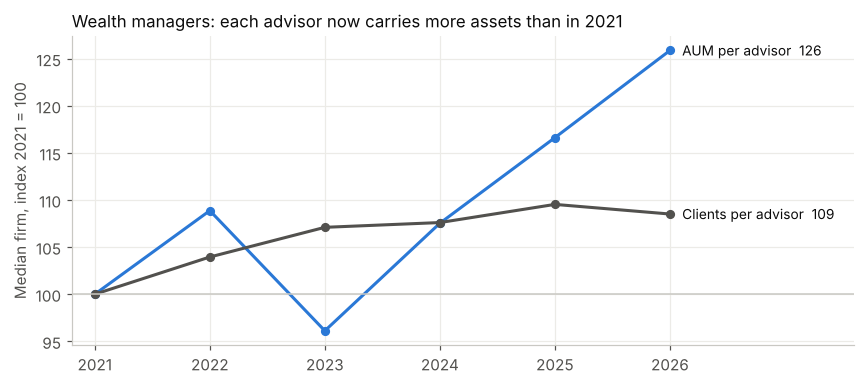

In [14]:
wm = panel[panel["wealth_manager"] & ~panel["digital_or_platform"] & (panel["advisors"] >= MIN_ADVISORS_CAPACITY)]
trend = wm.groupby("year").agg(firms=("sec_number", "count"),
                               median_aum_per_advisor=("aum_per_advisor", "median"),
                               median_clients_per_advisor=("clients_per_advisor", "median"))
idx = trend[["median_aum_per_advisor", "median_clients_per_advisor"]] / trend.iloc[0][["median_aum_per_advisor", "median_clients_per_advisor"]] * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
labels = {"median_aum_per_advisor": "AUM per advisor", "median_clients_per_advisor": "Clients per advisor"}
for col, color in zip(idx.columns, [BLUE, MUTED]):
    ax.plot(idx.index, idx[col], color=color, lw=2, marker="o", ms=5)
    ax.annotate(f"{labels[col]}  {idx[col].iloc[-1]:.0f}", (idx.index[-1], idx[col].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.axhline(100, color="#c9c8c3", lw=1)
ax.set_xticks(idx.index)
ax.set_xlim(idx.index[0] - 0.2, idx.index[-1] + 1.6)
ax.set_ylabel("Median firm, index 2021 = 100")
ax.set_title("Wealth managers: each advisor now carries more assets than in 2021", loc="left", fontsize=11)
fig.tight_layout()

print(trend.assign(median_aum_per_advisor=trend["median_aum_per_advisor"].map(money),
                   median_clients_per_advisor=trend["median_clients_per_advisor"].round(0)).to_string())

In [15]:
def understaffed(h, n=TOP_N, organic=True):
    d = g[(g[f"advisors_{h}y_ago"] >= MIN_BASE_ADVISORS) & (g[f"aum_{h}y_ago"] >= MIN_BASE_AUM)
          & (g[f"aum_cagr_{h}y"] > 0) & g[f"staffing_gap_{h}y"].notna()]
    d = d[~d[f"step_change_{h}y"] & ~d[f"advisor_step_{h}y"] & ~d["succession_any"]] if organic else d
    return top_by_segment(d, f"staffing_gap_{h}y", n)


def show_understaffed(h):
    t = understaffed(h)
    return pd.DataFrame({
        "Segment": t["segment"].astype(str), "SEC#": t["sec_number"], "Firm": t["firm_name"].str.title(),
        "HQ": hq(t),
        f"AUM {LATEST - h}→{LATEST}": t[f"aum_{h}y_ago"].map(money) + " → " + t["aum"].map(money),
        f"Advisors {LATEST - h}→{LATEST}": t[f"advisors_{h}y_ago"].map("{:,.0f}".format) + " → " + t["advisors"].map("{:,.0f}".format),
        "AUM CAGR": t[f"aum_cagr_{h}y"].map(pct), "Advisor CAGR": t[f"advisor_cagr_{h}y"].map(pct),
        "Gap (pts/yr)": (t[f"staffing_gap_{h}y"] * 100).map("{:+.0f}".format),
        "Wealth mgr": t["wealth_manager"].map({True: "yes", False: ""}),
    }).reset_index(drop=True)


share_gap = {h: (g.loc[(g[f"advisors_{h}y_ago"] >= MIN_BASE_ADVISORS) & (g[f"aum_{h}y_ago"] >= MIN_BASE_AUM),
                       f"staffing_gap_{h}y"] > 0).mean() for h in (1, 3, 5)}
print("Share of established firms whose AUM grew faster than advisor headcount:",
      ", ".join(f"{h}y {v:.0%}" for h, v in share_gap.items()))

Share of established firms whose AUM grew faster than advisor headcount: 1y 73%, 3y 78%, 5y 76%


### Under-staffed, 1 year

In [16]:
show_understaffed(1)

,Segment,SEC#,Firm,HQ,AUM 2025→2026,Advisors 2025→2026,AUM CAGR,Advisor CAGR,Gap (pts/yr),Wealth mgr
0,<$1B,801-131171,Lincoln Energy Holdings Llc,"Englewood, CO",$109M → $315M,8 → 7,+190%,-12%,+202,
1,<$1B,801-79917,"First Citizens Asset Management, Inc","Raleigh, NC",$167M → $465M,33 → 32,+178%,-3%,+181,yes
2,<$1B,801-126844,Derby Copeland Capital,"New York, NY",$141M → $396M,18 → 18,+180%,+0%,+180,
3,<$1B,801-126465,Bg America Llc,"New York, NY",$111M → $311M,5 → 5,+179%,+0%,+179,
4,<$1B,801-131318,The Life Wealth Group,"Winter Garden, FL",$178M → $491M,9 → 9,+176%,+0%,+176,yes
5,$1B-$10B,801-121249,K5 Global Advisor Llc,",",$2.1B → $5.8B,6 → 5,+183%,-17%,+200,
6,$1B-$10B,801-120065,Aliya Capital Partners Llc,"Miami, FL",$2.0B → $5.3B,8 → 6,+170%,-25%,+195,
7,$1B-$10B,801-120001,"Tcg Crossover Management, Llc","Palo Alto, CA",$1.8B → $5.1B,10 → 9,+181%,-10%,+191,
8,$1B-$10B,801-119968,Washington Harbour Partners Lp,"Arlington, VA",$1.6B → $4.7B,7 → 8,+192%,+14%,+177,
9,$1B-$10B,801-122935,Impactassets Capital Partners Pb Llc,"Bethesda, MD",$1.8B → $4.9B,15 → 15,+174%,+0%,+174,


### Under-staffed, 3 years

In [17]:
show_understaffed(3)

,Segment,SEC#,Firm,HQ,AUM 2023→2026,Advisors 2023→2026,AUM CAGR,Advisor CAGR,Gap (pts/yr),Wealth mgr
0,<$1B,801-126068,Prime Quadrant,"Toronto, Canada",$188M → $849M,5 → 3,+65%,-16%,+81,yes
1,<$1B,801-116996,"First Eagle Separate Account Management, Llc","New York, NY",$157M → $908M,38 → 40,+80%,+2%,+78,
2,<$1B,801-127861,Hurricane Capital Advisors Llc,"New York, NY",$181M → $603M,10 → 4,+49%,-26%,+76,
3,<$1B,801-126102,Encompass More Asset Management Llc,"Danville, CA",$113M → $985M,32 → 85,+106%,+38%,+67,yes
4,<$1B,801-127384,Ancient Management Lp D/B/A Ancient,"New York, NY",$250M → $839M,8 → 5,+50%,-15%,+64,
5,$1B-$10B,801-125864,Forest Avenue Capital Management Lp,"Miami, FL",$237M → $2.4B,7 → 5,+116%,-11%,+127,
6,$1B-$10B,801-121194,Metaurus Advisors Llc,"Westport, CT",$145M → $1.6B,5 → 5,+122%,+0%,+122,
7,$1B-$10B,801-119979,"Prysm Capital, L.P.","Princeton, NJ",$827M → $6.9B,8 → 9,+102%,+4%,+98,
8,$1B-$10B,801-126075,"Buck Wealth Strategies, Llc","Denver, CO",$134M → $1.6B,16 → 39,+130%,+35%,+96,yes
9,$1B-$10B,801-122996,Doubleline Etf Adviser Lp,"Tampa, FL",$325M → $2.1B,105 → 89,+87%,-5%,+92,


### Under-staffed, 5 years

In [18]:
show_understaffed(5)

,Segment,SEC#,Firm,HQ,AUM 2021→2026,Advisors 2021→2026,AUM CAGR,Advisor CAGR,Gap (pts/yr),Wealth mgr
0,<$1B,801-117464,Ifc Core Investment Management Llc,"Raleigh, NC",$105M → $742M,26 → 21,+48%,-4%,+52,
1,<$1B,801-115230,"Flowstone Partners, Llc",",",$106M → $767M,5 → 5,+48%,+0%,+48,
2,<$1B,801-63410,Westwood Wealth Management,"Dallas, TX",$123M → $750M,17 → 14,+44%,-4%,+47,
3,<$1B,801-115013,"Park Capital Management, Llc","Madison, WI",$176M → $868M,6 → 5,+38%,-4%,+41,yes
4,<$1B,801-108432,"Diversified Resources, Llc","Warwick, RI",$163M → $269M,5 → 1,+10%,-28%,+38,yes
5,$1B-$10B,801-120019,Carrick Lane Llc,"New York, NY",$159M → $3.0B,6 → 6,+80%,+0%,+80,yes
6,$1B-$10B,801-119015,"Mwp Advisory, Llc","New York, NY",$106M → $1.6B,7 → 7,+73%,+0%,+73,
7,$1B-$10B,801-120919,Wincoram Asset Management Llc,"Houston, TX",$414M → $8.2B,7 → 11,+82%,+9%,+72,
8,$1B-$10B,801-119203,"Quid Capital Group Holdings, Llc","Santa Monica, CA",$791M → $7.8B,8 → 6,+58%,-6%,+64,
9,$1B-$10B,801-66719,Cardinal Point Wealth Management,"Toronto, On, Canada",$339M → $4.8B,17 → 24,+70%,+7%,+63,yes


**Commentary.**
* Under-staffing is the norm, not the exception. About three-quarters of established firms grew
  AUM faster than their advisor teams at every horizon. The median wealth manager's AUM per advisor
  rose ~27% from 2021 to 2026 (≈$60M → $76M), while clients per advisor rose ~9%: each advisor is
  responsible for more money *and* more relationships. Market appreciation does part
  of this, since assets rise with markets while headcount doesn't, but the leaders above are far
  beyond any market move.
* The leaders doubled or tripled AUM on a flat or *shrinking* advisor team. Either they already
  run unusually efficient operations, or the strain is landing on advisors and staff. Both are
  good conversations for Nevis.
* 1-year gaps are noisy, because one large mandate or market swing moves them. **3-year gaps are
  the most decision-useful signal:** sustained, but recent.

## 8. So what for Nevis

**Market structure.**
* Wealth managers are about two-thirds of RIAs under $1B, a third of the $1–10B segment and a
  small minority above $10B. Nevis's enterprise motion ($10B+) is therefore hunting in a
  **small, nameable pool** of a couple of hundred firms. The list below can go straight into a CRM.
* The median wealth manager's AUM per advisor keeps rising. Advisor capacity is a structural,
  industry-wide constraint, which is the core Nevis thesis, now with numbers.

**A prioritised target list.** One score combining all three questions. Universe: human-advised
wealth managers with ≥ $1B AUM, ≥ 5 advisors three years ago, and a full 3-year history. Each
firm gets a percentile rank within this universe on:
1. 3-year AUM CAGR (momentum)
2. 3-year staffing gap (strain is growing)
3. clients per advisor (strain right now)

The score is the average of the three. M&A / step-change firms are kept (integration is a strong
buying moment) but flagged, so a strategist knows which story to lead with.

In [19]:
t = g[g["wealth_manager"] & ~g["digital_or_platform"] & (g["aum"] >= 1e9)
      & g["aum_cagr_3y"].notna() & g["staffing_gap_3y"].notna() & g["clients_per_advisor"].notna()
      & (g["advisors_3y_ago"] >= MIN_BASE_ADVISORS) & ~g["advisor_step_3y"]].copy()
for c in ["aum_cagr_3y", "staffing_gap_3y", "clients_per_advisor"]:
    t[f"pctl_{c}"] = t[c].rank(pct=True)
t["nevis_score"] = t[[c for c in t if c.startswith("pctl_")]].mean(axis=1)
targets = t.sort_values("nevis_score", ascending=False)

print(f"Scored universe: {len(t):,} wealth managers >= $1B "
      f"({t['segment'].value_counts().reindex(SEGMENTS[1:]).to_dict()})")
top = targets.head(25)
pd.DataFrame({
    "Rank": range(1, len(top) + 1), "SEC#": top["sec_number"], "Firm": top["firm_name"].str.title(),
    "Website / social": top["website"].fillna(top["social_url"]).fillna(""), "HQ": hq(top),
    "Segment": top["segment"].astype(str), "AUM": top["aum"].map(money),
    "AUM CAGR 3y": top["aum_cagr_3y"].map(pct), "Advisor CAGR 3y": top["advisor_cagr_3y"].map(pct),
    "Clients / advisor": top["clients_per_advisor"].map("{:,.0f}".format),
    "Score": top["nevis_score"].map("{:.2f}".format),
    "Flag": flag(top, 3),
}).reset_index(drop=True)

Scored universe: 1,349 wealth managers >= $1B ({'$1B-$10B': 1165, '$10B-$50B': 137, '>$50B': 47})


,Rank,SEC#,Firm,Website / social,HQ,Segment,AUM,AUM CAGR 3y,Advisor CAGR 3y,Clients / advisor,Score,Flag
0,1,801-116970,Vise Ai Advisors,www.vise.com,"New York City, NY",$1B-$10B,$8.5B,+161%,+6%,820,1.00,M&A / step change
1,2,801-18273,Missionsquare Retirement,research.missionsq.org,"Washington, DC",$1B-$10B,$6.3B,+114%,-7%,252,0.98,M&A / step change
2,3,801-125744,Concentric,www.concentricinnovation.com,"Walnut Creek, CA",$10B-$50B,$13.9B,+93%,+47%,336,0.98,
3,4,801-126770,Keating Financial Advisory Services,www.keatingkc.com,"Manhattan, KS",$1B-$10B,$1.5B,+75%,+0%,213,0.97,M&A / step change
4,5,801-108767,Facet,www.facetwealth.com,"West Palm Beach, FL",$1B-$10B,$7.6B,+54%,-11%,224,0.96,
5,6,801-127739,Corevision Financial Group,www.corevisionfg.com,"Shelbyville, IN",$1B-$10B,$1.2B,+61%,+0%,219,0.96,M&A / step change
6,7,801-120505,Revisor Wealth Management Llc,https://www.facebook.com/revisorpartners/,"Akron, OH",$1B-$10B,$2.5B,+40%,-4%,447,0.96,
7,8,801-107723,"Aptus Capital Advisors, Llc",www.aptuscapitaladvisors.com,"Fairhope, AL",$10B-$50B,$14.1B,+49%,+18%,490,0.96,
8,9,801-58098,"T. Rowe Price Advisory Services, Inc.",www.troweprice.com,"Owings Mills, MD",$1B-$10B,$5.9B,+63%,+26%,205,0.95,
9,10,801-113505,Provenance Wealth Advisors,https://www.linkedin.com/company/provenance-we...,"Fort Lauderdale, FL",$1B-$10B,$3.6B,+80%,+0%,160,0.95,M&A / step change


In [20]:
# Same scoring, enterprise only (>= $10B) — Nevis's Deployment Strategist territory
ent = targets[targets["aum"] >= 10e9].head(15)
pd.DataFrame({
    "Rank": range(1, len(ent) + 1), "SEC#": ent["sec_number"], "Firm": ent["firm_name"].str.title(),
    "HQ": hq(ent), "AUM": ent["aum"].map(money), "AUM CAGR 3y": ent["aum_cagr_3y"].map(pct),
    "Advisors": ent["advisors"].map("{:,.0f}".format), "Advisor CAGR 3y": ent["advisor_cagr_3y"].map(pct),
    "Clients / advisor": ent["clients_per_advisor"].map("{:,.0f}".format),
    "Score": ent["nevis_score"].map("{:.2f}".format), "Flag": flag(ent, 3),
}).reset_index(drop=True)

,Rank,SEC#,Firm,HQ,AUM,AUM CAGR 3y,Advisors,Advisor CAGR 3y,Clients / advisor,Score,Flag
0,1,801-125744,Concentric,"Walnut Creek, CA",$13.9B,+93%,16,+47%,336,0.98,
1,2,801-107723,"Aptus Capital Advisors, Llc","Fairhope, AL",$14.1B,+49%,26,+18%,490,0.96,
2,3,801-107319,"Ae Wealth Management, Llc","Topeka, KS",$49.8B,+37%,448,+0%,286,0.94,
3,4,801-68177,"O'Shaughnessy Asset Management, Llc","Stamford, CT",$19.8B,+46%,53,+21%,236,0.92,
4,5,801-107426,"Steward Partners Investment Advisory, Llc","Stamford, CT",$36.7B,+45%,310,+14%,169,0.91,
5,6,801-20406,Cetera Investment Advisers Llc,"Schaumburg, IL",$256.8B,+97%,"9,049",+48%,93,0.88,M&A / step change
6,7,801-79876,Newedge Advisors,"New Orleans, LA",$43.2B,+50%,515,+9%,97,0.88,
7,8,801-57434,Wells Fargo Advisors,"St. Louis, MO",$252.3B,+35%,"2,366",+11%,198,0.88,
8,9,801-54859,"Osaic Wealth, Inc.","Scottsdale, AZ",$234.9B,+100%,"7,143",+51%,89,0.87,M&A / step change
9,10,801-126555,"Concurrent Investment Advisors, Llc","Tampa, FL",$15.7B,+383%,160,+17%,83,0.87,M&A / step change


**How a Deployment Strategist would use this.** Sort the CRM by `nevis_score` within segment.
Lead with momentum for high-growth firms ("you've grown X% a year, and your team hasn't"), and
with capacity for high clients-per-advisor firms ("each advisor carries N relationships").
Firms flagged for M&A get an integration-led pitch: "consolidate onto one platform as you absorb
books".

**Next steps for this analysis:**
* enrich websites and contacts from IAPD Schedule D
* refresh monthly as new ADV snapshots land
* roll multi-registrant groups up to the parent brand using Item 7 affiliations
* add a market-adjusted growth measure (firm growth minus the segment median)

## 9. Assumptions, edge cases & limitations

| Topic | Assumption / handling | Impact |
|---|---|---|
| **Timing of AUM** | Each snapshot shows a firm's AUM as of its *latest filing*. Most firms update AUM once a year, in the annual amendment due ~90 days after fiscal year-end (hence the March filing spike). | "2026 AUM" mostly means AUM at FY-end 2025. Growth compares like-for-like filings one, three and five years apart. |
| **Regulatory AUM** | Item 5.F(2)(c), discretionary + non-discretionary | Includes some double counting (sub-advised assets). Fine for ranking, not for industry sizing. |
| **Advisors** | Item 5.B(1), employees performing investment advisory functions *including research* | Overstates client-facing advisors at research-heavy firms. Could refine with 5.B(3) (state-registered IARs) for wealth firms. |
| **Clients** | Σ 5.D(1) + 5.C(1). "Fewer than 5" boxes imputed as 2. Dollar typos in 5.C(1) dropped (≈5–10 firms a year). | Small firms' counts can be ±2 per category. Totals are no longer dominated by typos. |
| **Market effect** | Growth is *not* market-adjusted. Each table shows the segment median as context. | 2021→2022 was a drawdown year, 2023→2026 a strong market. Compare firms to peers, not to zero. |
| **Firm identity** | Firm = SEC# (801-). Re-registrations under a new SEC# and multi-entity groups (e.g. separate RIAs for one brand) are not merged. | Some "new" fast growers are reorganisations; flagged via the step-change rule. |
| **Survivorship** | Growth requires presence in both years. Firms that deregistered or moved to state registration drop out. | Rankings describe surviving firms, which is the right population for prospecting. |
| **Segment boundaries** | Lower bound inclusive: exactly $1B is in "$1B–$10B". | Negligible. |
| **Websites** | The bulk file holds one URL per firm-year (often a social profile). Best domain chosen across six years by firm-name match. | ~80% of firms get a website: ~2/3 name-matched (high confidence), ~1/8 "latest" (lower confidence, flagged in `website_source`). Full lists live in IAPD Schedule D 1.I. Some large managers (e.g. Vanguard, Fidelity) report only social links, so their Website is blank. `social_url` keeps company pages only; personal LinkedIn profiles are dropped. |
| **Extreme ratios** | Firms reporting large AUM with 0–1 advisors are kept in the data table as filed. Zero denominators give blank ratios. | They are excluded from every ranking by the minimum-advisor thresholds, so they never reach a leaderboard. |
| **Platforms** | > 1,000 clients per advisor = digital / platform adviser | A heuristic. A few large human-advised firms with big call-centre models may be caught; they stay in the data table. |
| **Wealth-manager flag** | ≥ 50% of AUM from individuals + HNW clients | A judgment threshold. The Excel workbook keeps `pct_aum_individuals` so it can be moved. |

In [21]:
# ---- Export everything a reviewer or a sales team would want -------------------------------
cols_latest = (["sec_number", "crd", "firm_name", "website", "website_source", "social_url", "city", "state", "segment",
                "aum", "clients", "aum_per_client", "employees", "advisors", "aum_per_advisor",
                "clients_per_advisor", "wealth_manager", "digital_or_platform", "pct_aum_individuals", "pct_aum_hnw", "filing_date"]
               + [f"{m}_{h}y" for h in (1, 3, 5) for m in ("aum_cagr", "advisor_cagr", "staffing_gap", "step_change", "advisor_step")]
               + ["succession_any"])

all_cap = g[(g["advisors"] >= MIN_ADVISORS_CAPACITY) & (g["aum"] > 0)]
sheets = {
    "README": pd.DataFrame({"note": [
        "Source: SEC Form ADV Part 1A bulk snapshots, Sept 2021-Sept 2026 (see notebook Section 1).",
        f"Growth rankings require base-year AUM >= ${MIN_BASE_AUM/1e6:.0f}M; staffing gap requires >= {MIN_BASE_ADVISORS} base-year advisors.",
        f"Capacity rankings require >= {MIN_ADVISORS_CAPACITY} advisors; 'capacity_wealth' restricts to firms with >= 50% of AUM from individuals/HNW and excludes digital/platform advisers (>1,000 clients per advisor).",
        "'organic' sheets exclude firms flagged step_change or succession_any; 'incl_mna' sheets keep them.",
        "step_change = AUM more than tripled in a single year within the window; advisor_step = advisors more than halved or tripled in a single year; succession_any = Item 4.A succession reported.",
        "Segment = latest-year AUM band. All $ in USD."]}),
    "firms_2026": g[cols_latest].sort_values("aum", ascending=False),
    "segment_summary": seg.reset_index(),
    "industry_trend": trend.reset_index(),
    **{f"fastest_{h}y_organic": fastest(h, 25)[cols_latest] for h in (1, 3, 5)},
    **{f"fastest_{h}y_incl_mna": fastest(h, 25, organic=False)[cols_latest] for h in (1, 3, 5)},
    "capacity_wealth": top_by_segment(cap_universe, "aum_per_advisor", 25)[cols_latest],
    "capacity_all_firms": top_by_segment(all_cap, "aum_per_advisor", 25)[cols_latest],
    **{f"understaffed_{h}y": understaffed(h, 25)[cols_latest] for h in (1, 3, 5)},
    "nevis_targets": targets.head(100)[["nevis_score"] + cols_latest],
}
with pd.ExcelWriter(OUT / "nevis_ria_analysis.xlsx", engine="xlsxwriter") as xw:
    money_fmt = xw.book.add_format({"num_format": "#,##0"})
    pct_fmt = xw.book.add_format({"num_format": "0.0%"})
    for name, df in sheets.items():
        df = tidy(df)
        for c in df.select_dtypes(include=["datetimetz", "datetime"]).columns:
            df[c] = df[c].dt.date
        if "segment" in df:
            df["segment"] = df["segment"].astype(str)
        df.to_excel(xw, sheet_name=name[:31], index=False)
        ws = xw.sheets[name[:31]]
        ws.freeze_panes(1, 0)
        for i, c in enumerate(df.columns):  # readable number formats in Excel
            c = str(c)
            if c in ("aum", "aum_per_client", "aum_per_advisor", "clients", "employees", "advisors") or c.endswith("y_ago"):
                ws.set_column(i, i, 16, money_fmt)
            elif c.startswith(("pct_", "aum_cagr", "advisor_cagr", "clients_cagr", "staffing_gap")):
                ws.set_column(i, i, 12, pct_fmt)
print("wrote outputs/nevis_ria_analysis.xlsx with sheets:", ", ".join(sheets))

wrote outputs/nevis_ria_analysis.xlsx with sheets: README, firms_2026, segment_summary, industry_trend, fastest_1y_organic, fastest_3y_organic, fastest_5y_organic, fastest_1y_incl_mna, fastest_3y_incl_mna, fastest_5y_incl_mna, capacity_wealth, capacity_all_firms, understaffed_1y, understaffed_3y, understaffed_5y, nevis_targets
